# Чекпоинт 2. EDA: прогноз цен Day-Ahead

Данные: data_with_features.csv, почасовые данные с 01.01.2024 по 31.12.2025 (время Будапешта).

Структура:

1. Обзор датасета и качество данных
2. Распределения, выбросы, отрицательные цены
3. Сезонность, связи признаков с ценой, лаги, ACF/PACF, стационарность
4. Выводы EDA и практическая применимость

In [2]:
%pip install -q statsmodels -i https://pypi.tuna.tsinghua.edu.cn/simple

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# папка для картинок
os.makedirs("figures", exist_ok=True)

## 1. Обзор данных и их качество

In [2]:
df = pd.read_csv("data_with_features.csv")
print(df.shape)
df.head()

(17544, 8)


,timestamp,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
0,2023-12-31 23:00:00+00:00,0.10,4068.18,0.0,-1089.2,86.58,1900.0,5.28
1,2024-01-01 00:00:00+00:00,0.01,3892.38,0.0,-971.5,57.10,1900.0,5.37
2,2024-01-01 01:00:00+00:00,0.04,3644.58,0.0,-860.7,44.13,1900.0,5.49
3,2024-01-01 02:00:00+00:00,0.01,3493.50,0.0,-733.1,65.15,1900.0,5.57
4,2024-01-01 03:00:00+00:00,0.01,3454.03,0.0,-700.0,93.58,1900.0,5.53


In [3]:
df.tail()

,timestamp,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
17539,2025-12-31 18:00:00+00:00,124.37,5407.65,0.0,-2105.8,113.10,1920.0,-2.72
17540,2025-12-31 19:00:00+00:00,115.53,5257.10,0.0,-1944.2,122.05,1920.0,-2.60
17541,2025-12-31 20:00:00+00:00,113.56,5308.78,0.0,-1999.6,132.15,1920.0,-2.44
17542,2025-12-31 21:00:00+00:00,108.72,5326.05,0.0,-1974.3,138.50,1920.0,-2.29
17543,2025-12-31 22:00:00+00:00,90.18,5352.90,0.0,-1925.5,145.45,1920.0,-2.11


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   timestamp                  17544 non-null  object 
 1   price_eur_mwh              17544 non-null  float64
 2   demand_forecast_mwh        17544 non-null  float64
 3   solar_forecast_mwh         17544 non-null  float64
 4   net_exchange_forecast_mwh  17544 non-null  float64
 5   wind_forecast_mwh          17544 non-null  float64
 6   nuclear_forecast_mwh       17544 non-null  float64
 7   temperature_forecast_c     17544 non-null  float64
dtypes: float64(7), object(1)
memory usage: 1.1+ MB


Type of timestamp = object. Из строки нельзя достать время. Поэтому превращаем её в настоящий тип даты-времени через pd.to_datetime.

Время в файле в UTC. Будапешт зимой живёт на час впереди (UTC+1). Переводим в часовой пояс Будапешта.

In [5]:
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["time"] = df["timestamp"].dt.tz_convert("Europe/Budapest")

print("начало:", df["time"].min())
print("конец:", df["time"].max())

начало: 2024-01-01 00:00:00+01:00
конец: 2025-12-31 23:00:00+01:00


In [6]:
df[["timestamp", "time"]].tail()

,timestamp,time
17539,2025-12-31 18:00:00+00:00,2025-12-31 19:00:00+01:00
17540,2025-12-31 19:00:00+00:00,2025-12-31 20:00:00+01:00
17541,2025-12-31 20:00:00+00:00,2025-12-31 21:00:00+01:00
17542,2025-12-31 21:00:00+00:00,2025-12-31 22:00:00+01:00
17543,2025-12-31 22:00:00+00:00,2025-12-31 23:00:00+01:00


In [7]:
df[["timestamp", "time"]].iloc[4360:4363]

,timestamp,time
4360,2024-06-30 15:00:00+00:00,2024-06-30 17:00:00+02:00
4361,2024-06-30 16:00:00+00:00,2024-06-30 18:00:00+02:00
4362,2024-06-30 17:00:00+00:00,2024-06-30 19:00:00+02:00


### Пропуски, дубликаты, странные значения

In [8]:
print("Пропуски:")
print(df.isna().sum())

print("\nДубликаты времени:", df["timestamp"].duplicated().sum())

print("\nsolar < 0:", (df["solar_forecast_mwh"] < 0).sum()) #невозможные значения
print("wind < 0:", (df["wind_forecast_mwh"] < 0).sum())
print("demand <= 0:", (df["demand_forecast_mwh"] <= 0).sum())
print("цена < 0:", (df["price_eur_mwh"] < 0).sum())

Пропуски:
timestamp                    0
price_eur_mwh                0
demand_forecast_mwh          0
solar_forecast_mwh           0
net_exchange_forecast_mwh    0
wind_forecast_mwh            0
nuclear_forecast_mwh         0
temperature_forecast_c       0
time                         0
dtype: int64

Дубликаты времени: 0

solar < 0: 0
wind < 0: 0
demand <= 0: 0
цена < 0: 543


### Нет ли пропущенных часов?
Строим полный список часов от начала до конца и сравниваем с данными.

In [11]:
all_hours = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="h") #строит полный список часов от начала до конца, потом сравниваем его длину с данными
print("должно быть часов:", len(all_hours))
print("есть в данных:", len(df))

# переход на летнее/зимнее время: сколько часов в каждых сутках по Будапешту
hours_in_day = df.groupby(df["time"].dt.date).size()
print(hours_in_day.value_counts())
print(hours_in_day[hours_in_day != 24])

должно быть часов: 17544
есть в данных: 17544
24    727
23      2
25      2
Name: count, dtype: int64
time
2024-03-31    23
2024-10-27    25
2025-03-30    23
2025-10-26    25
dtype: int64


**Наблюдения:**
- пропусков и дубликатов нет, отрицательных значений solar/wind/demand тоже нет
- ряд непрерывный, все 17 544 часа на месте
- 4 дня, где 23 или 25 часов: это переход на летнее/зимнее время
- отрицательные цены есть (543 часа)

In [12]:
df.describe()

,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000
mean,104.658552,4932.654702,709.517923,-1096.129697,66.320306,1740.107361,12.610484
std,73.143194,849.932015,1021.831947,1332.193201,61.657125,222.590801,9.351000
min,-210.050000,2303.430000,0.000000,-5365.300000,0.550000,1372.250000,-7.030000
25%,72.830000,4290.282500,0.000000,-2064.225000,16.522500,1440.000000,4.880000
50%,97.675000,4860.755000,34.925000,-1299.750000,47.130000,1900.000000,12.050000
75%,126.352500,5504.685000,1266.182500,-219.200000,97.457500,1900.000000,19.990000
max,999.010000,7442.800000,4329.080000,3819.900000,291.830000,1949.500000,35.910000


In [13]:
df["price_eur_mwh"].describe()

count    17544.000000
mean       104.658552
std         73.143194
min       -210.050000
25%         72.830000
50%         97.675000
75%        126.352500
max        999.010000
Name: price_eur_mwh, dtype: float64

**Наблюдения:** средняя цена ~105 евро, медиана ~98 евро. Минимум −210 евро, максимум 999 евро, то есть разброс очень большой.
wind_forecast в среднем даёт всего ~66 МВт*ч, около 1% потребления, поэтому вряд ли сильно влияет на цену. net_exchange в основном отрицательный: Венгрия получает энергию от соседей (импорт).

## 2. Распределения и выбросы

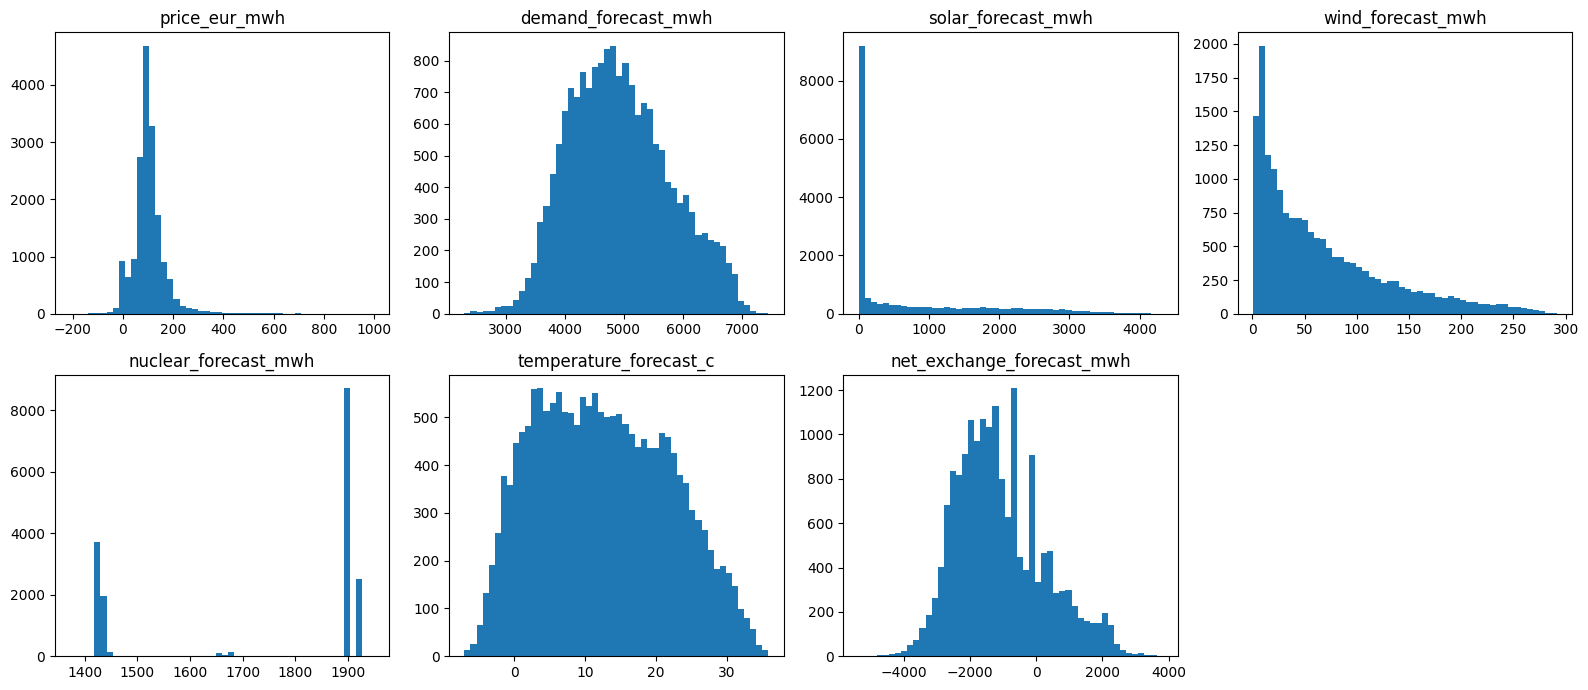

In [14]:
cols = ["price_eur_mwh", "demand_forecast_mwh", "solar_forecast_mwh", "wind_forecast_mwh",
        "nuclear_forecast_mwh", "temperature_forecast_c", "net_exchange_forecast_mwh"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()
for i, col in enumerate(cols):
    axes[i].hist(df[col], bins=50)
    axes[i].set_title(col)
axes[7].axis("off")
plt.tight_layout()
plt.savefig("figures/histograms.png")
plt.show()

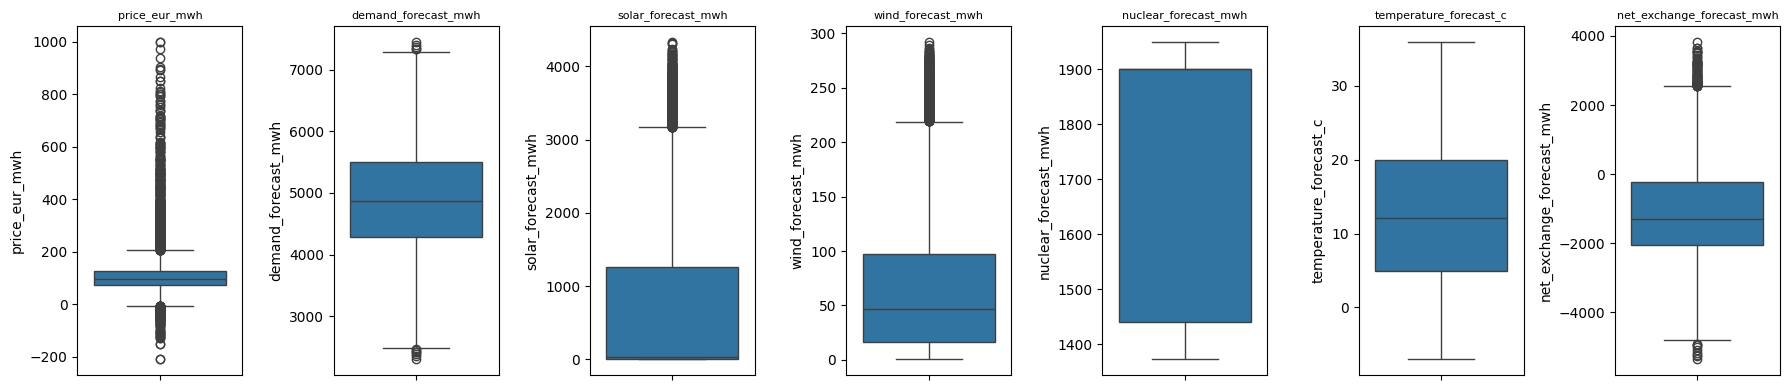

In [15]:
fig, axes = plt.subplots(1, 7, figsize=(18, 4))
for i, col in enumerate(cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
plt.tight_layout()
plt.savefig("figures/boxplots.png")
plt.show()

**Наблюдения:**
- цена сильно скошена вправо, много выбросов сверху
- у solar огромный столбик в нуле: это ночь
- nuclear принимает всего несколько значений (видимо, ремонты блоков АЭС)
- demand и temperature выглядят нормально

### Отрицательные и почти нулевые цены

In [16]:
df["hour"] = df["time"].dt.hour
df["month"] = df["time"].dt.month
df["dayofweek"] = df["time"].dt.dayofweek
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

neg = df[df["price_eur_mwh"] < 0]
low = df[df["price_eur_mwh"] <= 5]
print("отрицательных часов:", len(neg))
print("часов с ценой <= 5:", len(low))

отрицательных часов: 543
часов с ценой <= 5: 1002


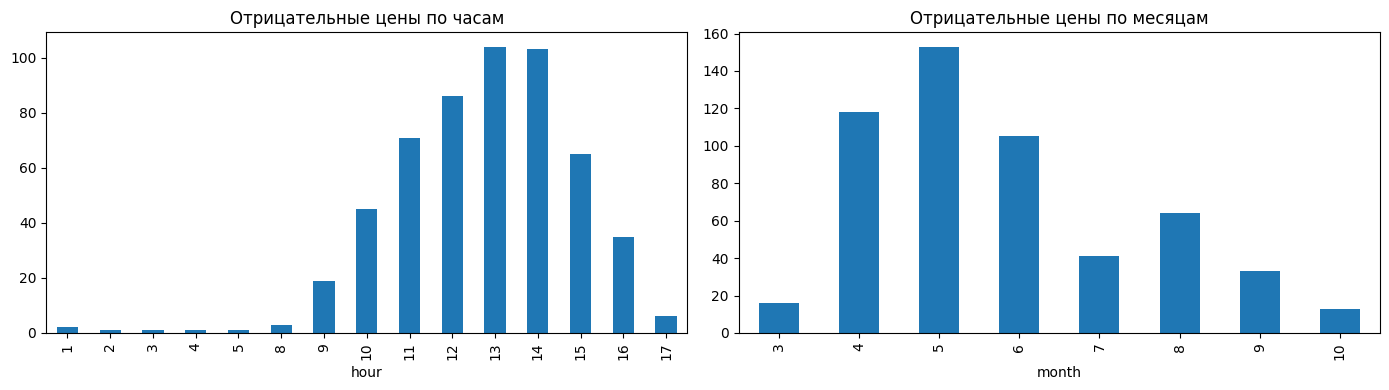

из них в выходные: 442


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
neg["hour"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Отрицательные цены по часам")
neg["month"].value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Отрицательные цены по месяцам")
plt.tight_layout()
plt.savefig("figures/negative_prices_hour_month.png")
plt.show()

print("из них в выходные:", neg["is_weekend"].sum())

In [18]:
# сравним признаки при отрицательной цене и в среднем
compare = pd.DataFrame({
    "цена < 0": neg[cols[1:]].median(),
    "все часы": df[cols[1:]].median(),
})
compare

,цена < 0,все часы
demand_forecast_mwh,3746.85,4860.755
solar_forecast_mwh,2821.93,34.925
wind_forecast_mwh,22.08,47.130
nuclear_forecast_mwh,1900.00,1900.000
temperature_forecast_c,22.91,12.050
net_exchange_forecast_mwh,1000.00,-1299.750


**Наблюдения:**
- отрицательных цен 543 (~3%), почти все днём с 10 до 16 часов
- в основном весной (апрель–июнь), зимой их нет
- больше половины (442) в выходные
- в эти часы solar очень большой, а demand маленький: солнца больше, чем нужно
- отрицательная цена появляется, когда солнца много, а потребления мало. Значит, модели важны не solar и demand по отдельности, а их соотношение.

### Выбросы

In [19]:
price = df["price_eur_mwh"]

q1 = price.quantile(0.25)
q3 = price.quantile(0.75)
iqr = q3 - q1
low_border = q1 - 1.5 * iqr
high_border = q3 + 1.5 * iqr
print("границы IQR:", low_border, high_border) 
print("выбросов по IQR:", ((price < low_border) | (price > high_border)).sum()) #от середины данных

z = np.abs(stats.zscore(price)) 
print("выбросов по z-score (|z| > 3):", (z > 3).sum()) #от среднего

границы IQR: -7.453749999999999 206.63625
выбросов по IQR: 1050
выбросов по z-score (|z| > 3): 274


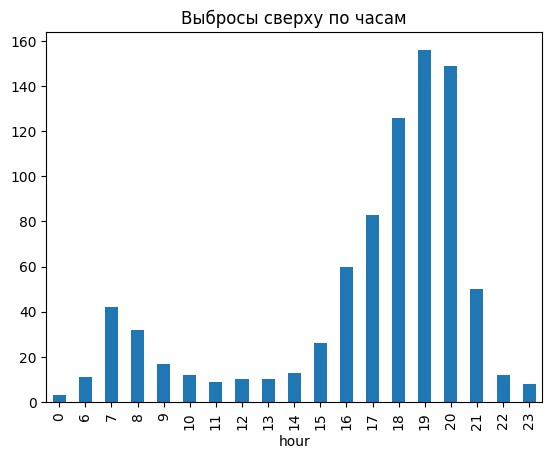

,time,price_eur_mwh,demand_forecast_mwh,temperature_forecast_c
4795,2024-07-18 20:00:00+02:00,999.01,6720.93,27.53
5922,2024-09-03 19:00:00+02:00,999.00,6538.58,26.59
5923,2024-09-03 20:00:00+02:00,974.80,6426.08,25.89
4627,2024-07-11 20:00:00+02:00,940.16,6570.58,30.68
5946,2024-09-04 19:00:00+02:00,903.41,6555.33,27.29
7601,2024-11-12 17:00:00+01:00,895.20,6767.53,3.24
4772,2024-07-17 21:00:00+02:00,891.37,6467.23,26.33
5921,2024-09-03 18:00:00+02:00,867.51,6480.93,28.69
4626,2024-07-11 19:00:00+02:00,850.05,6616.53,32.86
8321,2024-12-12 17:00:00+01:00,850.00,6880.78,1.09


In [20]:
# в какие часы большие выбросы
high_out = df[price > high_border]
high_out["hour"].value_counts().sort_index().plot(kind="bar")
plt.title("Выбросы сверху по часам")
plt.savefig("figures/price_outliers_by_hour.png")
plt.show()

# самые дорогие часы
df.sort_values("price_eur_mwh", ascending=False).head(10)[["time", "price_eur_mwh", "demand_forecast_mwh", "temperature_forecast_c"]]

**Наблюдения:**
- выбросы сверху почти все вечером (17–21 ч)
- самые дорогие часы: июль и сентябрь 2024 (жара, высокое потребление) и ноябрь–декабрь 2024
- это не ошибки, а реальные пики, удалять их нельзя
- дорого и при −5, и при +30, дешевле в комфортные +15...+20

### Асимметрия цены

skew: 3.351457211957218
skew после arcsinh: -0.8443868906696049


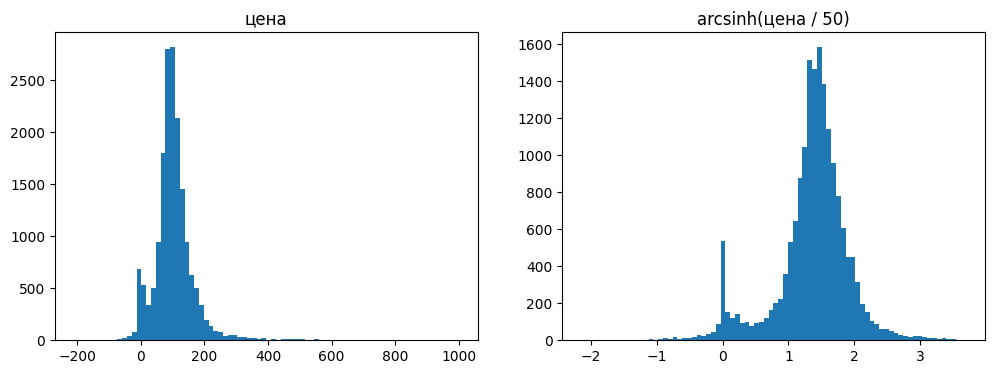

In [21]:
print("skew:", price.skew())

price_asinh = np.arcsinh(price / 50)
print("skew после arcsinh:", price_asinh.skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(price, bins=80)
axes[0].set_title("цена")
axes[1].hist(price_asinh, bins=80)
axes[1].set_title("arcsinh(цена / 50)")
plt.savefig("figures/price_transform.png")
plt.show()

**Наблюдения:** skew цены ~3.3, это очень сильная асимметрия. Логарифм не подходит из-за отрицательных цен. После arcsinh распределение стало гораздо ровнее, можно попробовать для линейных моделей.

## 3. Сезонность и связи с ценой

In [22]:
def get_season(month):
    if month in [12, 1, 2]:
        return "winter"
    elif month in [3, 4, 5]:
        return "spring"
    elif month in [6, 7, 8]:
        return "summer"
    else:
        return "autumn"

df["season"] = df["month"].apply(get_season)

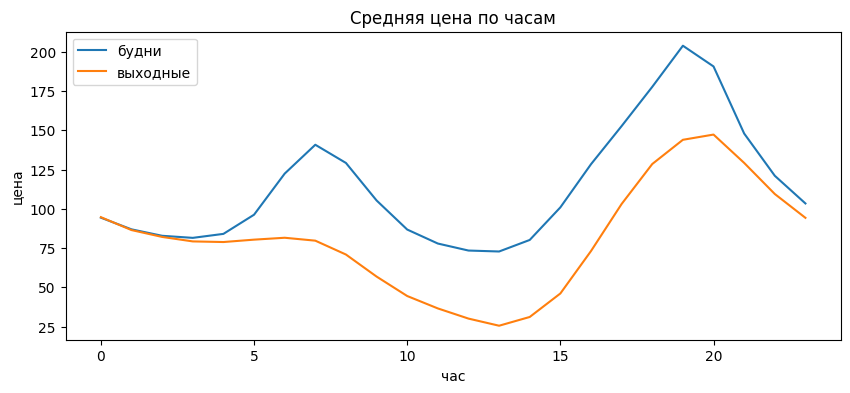

In [23]:
# средняя цена по часам: будни и выходные
weekday = df[df["is_weekend"] == 0].groupby("hour")["price_eur_mwh"].mean()
weekend = df[df["is_weekend"] == 1].groupby("hour")["price_eur_mwh"].mean()

plt.figure(figsize=(10, 4))
plt.plot(weekday, label="будни")
plt.plot(weekend, label="выходные")
plt.xlabel("час")
plt.ylabel("цена")
plt.title("Средняя цена по часам")
plt.legend()
plt.savefig("figures/price_hourly_profile.png")
plt.show()

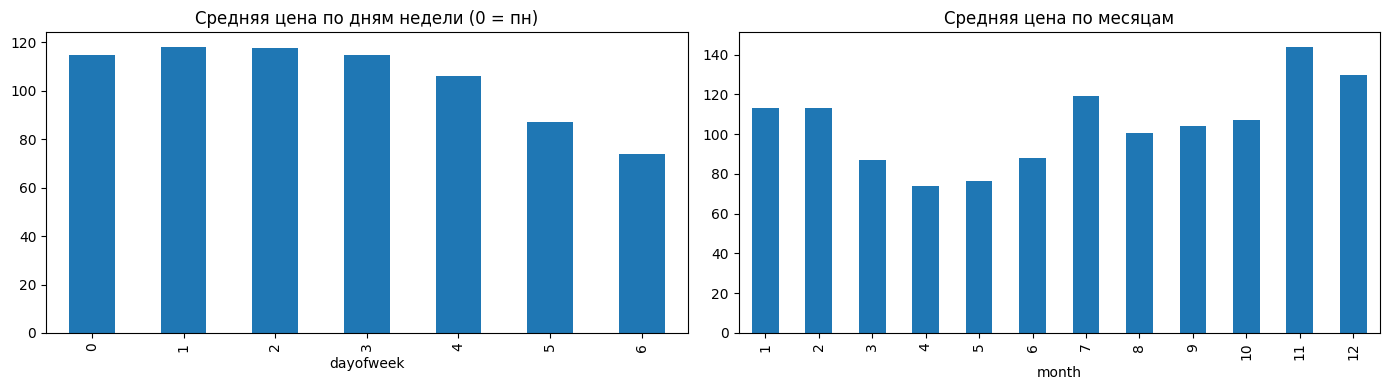

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("dayofweek")["price_eur_mwh"].mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("Средняя цена по дням недели (0 = пн)")
df.groupby("month")["price_eur_mwh"].mean().plot(kind="bar", ax=axes[1])
axes[1].set_title("Средняя цена по месяцам")
plt.tight_layout()
plt.savefig("figures/price_by_day_and_month.png")
plt.show()

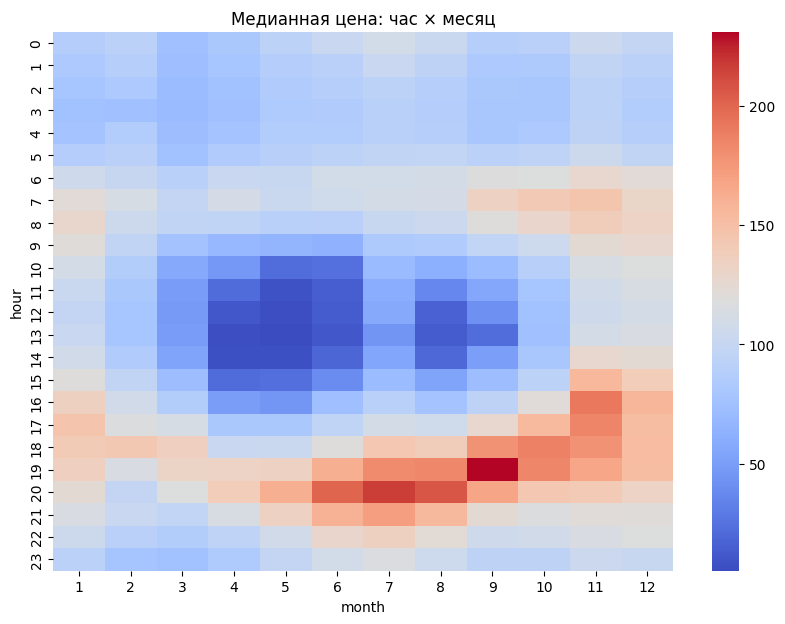

In [25]:
table = df.pivot_table(index="hour", columns="month", values="price_eur_mwh", aggfunc="median")
plt.figure(figsize=(10, 7))
sns.heatmap(table, cmap="coolwarm")
plt.title("Медианная цена: час × месяц")
plt.savefig("figures/price_heatmap_hour_month.png")
plt.show()

**Наблюдения:**
- в будни два пика: утром (7 ч) и вечером (19 ч, самый большой). Днём цена проседает
- в выходные днём цена падает очень сильно, утреннего пика нет
- пн–чт дороже всего, воскресенье дешевле всего
- на тепловой карте видно: весной и летом днём цена низкая (солнце), вечером высокая

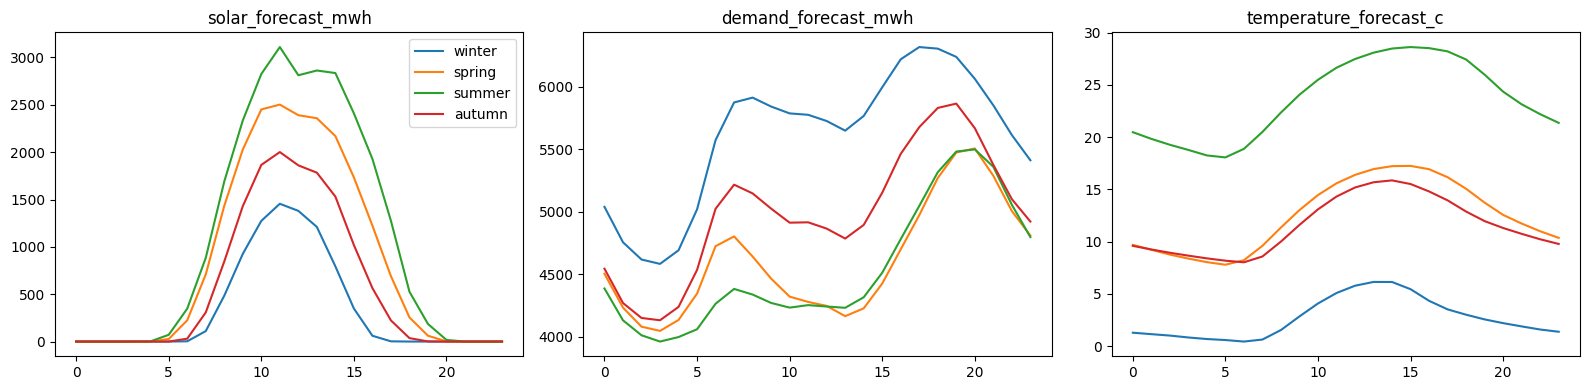

In [26]:
# как меняются solar, demand, temperature в течение суток в разные сезоны
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(["solar_forecast_mwh", "demand_forecast_mwh", "temperature_forecast_c"]):
    for season in ["winter", "spring", "summer", "autumn"]:
        data = df[df["season"] == season].groupby("hour")[col].mean()
        axes[i].plot(data, label=season)
    axes[i].set_title(col)
axes[0].legend()
plt.tight_layout()
plt.savefig("figures/seasonal_profiles.png")
plt.show()

**Наблюдения:** летом солнца сильно больше и оно светит дольше. Потребление выше зимой. Температура как и ожидалось.

### Корреляции

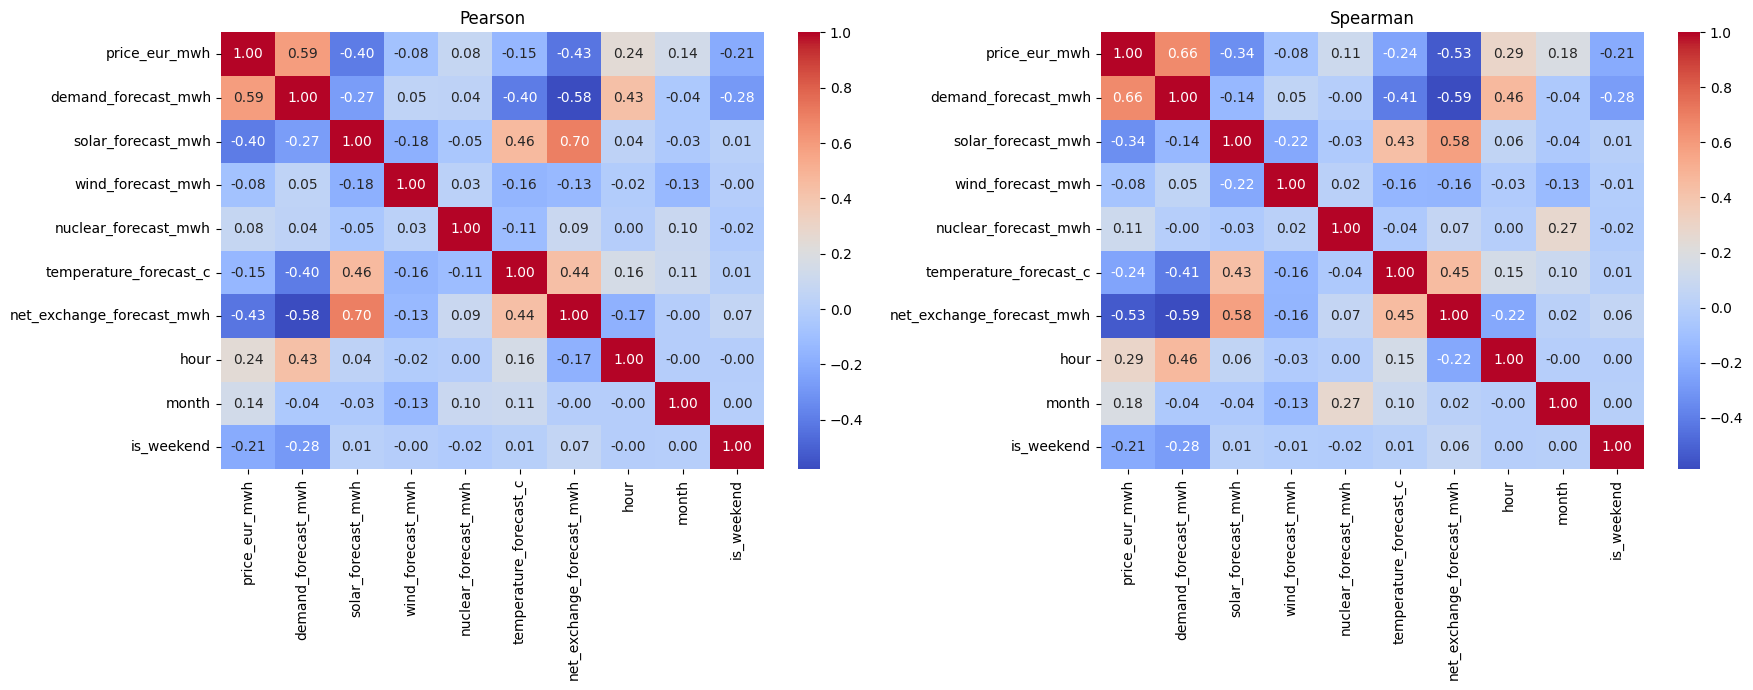

In [27]:
corr_cols = cols + ["hour", "month", "is_weekend"]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(df[corr_cols].corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Pearson")
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Spearman")
plt.tight_layout()
plt.savefig("figures/correlations.png")
plt.show()

In [28]:
df[corr_cols].corr(method="spearman")["price_eur_mwh"].sort_values()

net_exchange_forecast_mwh   -0.532057
solar_forecast_mwh          -0.338226
temperature_forecast_c      -0.242036
is_weekend                  -0.209757
wind_forecast_mwh           -0.077029
nuclear_forecast_mwh         0.109935
month                        0.176068
hour                         0.287416
demand_forecast_mwh          0.662393
price_eur_mwh                1.000000
Name: price_eur_mwh, dtype: float64

**Наблюдения:**
- с ценой сильнее всего связаны demand (+0.66) и net_exchange (−0.53), потом solar (−0.34)
- wind и nuclear почти не связаны с ценой
- признаки связаны между собой: solar и net_exchange (+0.58), demand и net_exchange (−0.59), demand и temperature (−0.41)
- Spearman чуть выше Pearson, значит связи не совсем линейные

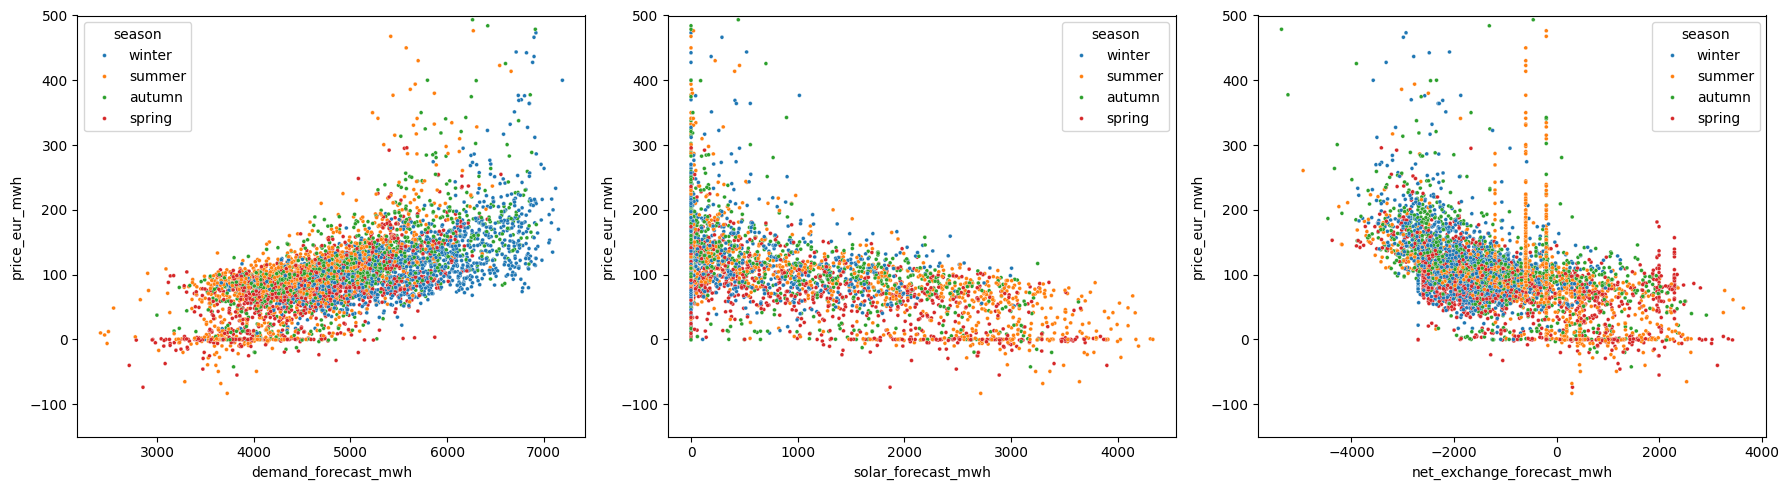

In [29]:
sample = df.sample(5000, random_state=42)  # берём часть точек, иначе график тяжёлый

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(["demand_forecast_mwh", "solar_forecast_mwh", "net_exchange_forecast_mwh"]):
    sns.scatterplot(data=sample, x=col, y="price_eur_mwh", hue="season", s=8, ax=axes[i])
    axes[i].set_ylim(-150, 500)
plt.tight_layout()
plt.savefig("figures/scatter_price.png")
plt.show()

**Наблюдения:** чем больше demand, тем выше цена. Чем больше solar, тем ниже. Отрицательные цены почти всегда при большом solar весной и летом.
В апреле–сентябре 2024 года у net_exchange много круглых значений (−600, −200 и т.п.), а с октября 2024 их нет совсем. Вероятно, сменилась методика расчёта прогноза в источнике данных, нужно уточнить.

### Лаги и скользящие средние

Важно: прогноз на завтра делается сегодня в 12:00. Цены за сегодня уже известны, за завтра нет.
Поэтому можно брать цену минимум 24 часа назад. Лаг в 1 час использовать нельзя.

In [30]:
df["price_lag_24"] = df["price_eur_mwh"].shift(24)
df["price_lag_168"] = df["price_eur_mwh"].shift(168)

# скользящие тоже сдвигаем на 24 часа, чтобы не подглядывать в будущее
df["rolling_mean_24"] = df["price_eur_mwh"].shift(24).rolling(24).mean()
df["rolling_std_24"] = df["price_eur_mwh"].shift(24).rolling(24).std()
df["rolling_mean_168"] = df["price_eur_mwh"].shift(24).rolling(168).mean()
df["rolling_std_168"] = df["price_eur_mwh"].shift(24).rolling(168).std()

lag_cols = ["price_lag_24", "price_lag_168", "rolling_mean_24", "rolling_std_24",
            "rolling_mean_168", "rolling_std_168"]
df[lag_cols + ["price_eur_mwh"]].corr()["price_eur_mwh"]

price_lag_24        0.778093
price_lag_168       0.687076
rolling_mean_24     0.375782
rolling_std_24      0.223832
rolling_mean_168    0.390755
rolling_std_168     0.228867
price_eur_mwh       1.000000
Name: price_eur_mwh, dtype: float64

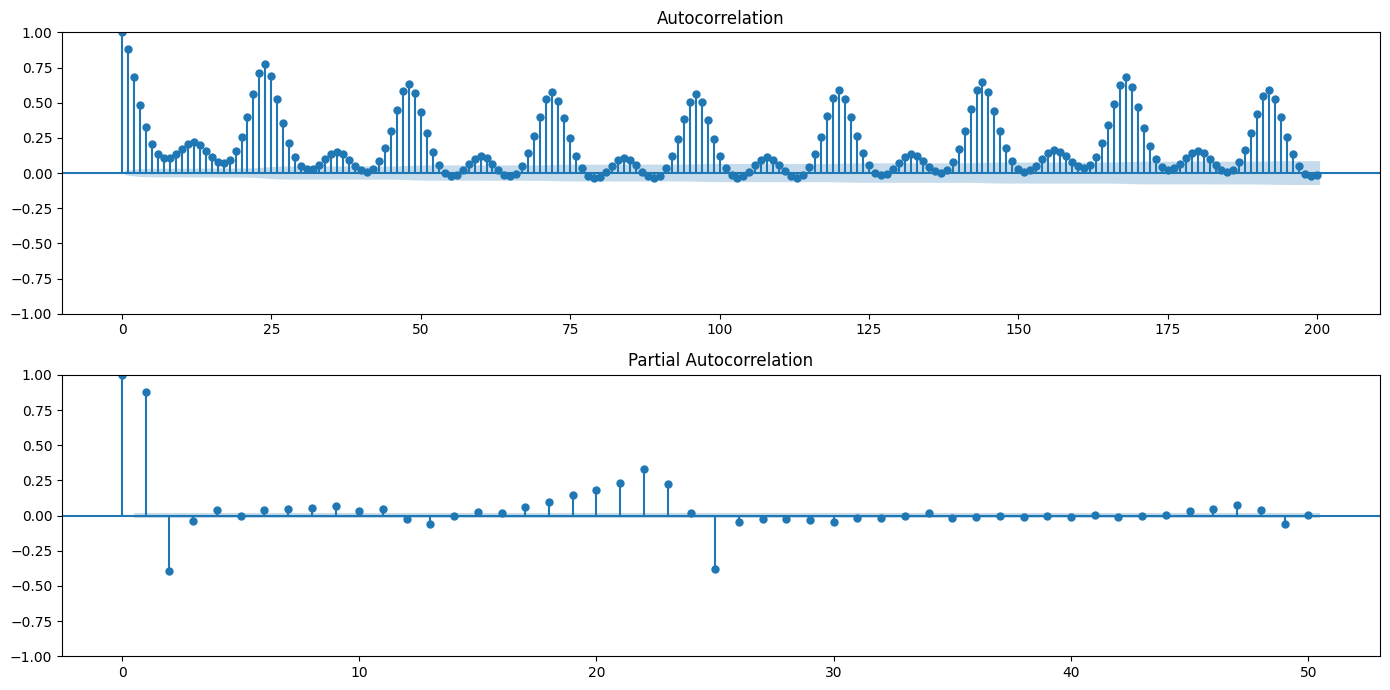

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(df["price_eur_mwh"], lags=200, ax=axes[0])
plot_pacf(df["price_eur_mwh"], lags=50, ax=axes[1])
plt.tight_layout()
plt.savefig("figures/acf_pacf.png")
plt.show()

**Наблюдения:**
- lag_24 и lag_168 сильно связаны с ценой (~0.78 и ~0.69), сильнее чем любой признак
- на ACF пики каждые 24 часа и большой на 168: цена повторяется по суткам и по неделям
- скользящие средние связаны слабее (~0.4)

### Стационарность (ADF-тест)

In [33]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

for col in ["price_eur_mwh", "price_lag_24", "price_lag_168"]:
    result = adfuller(df[col].dropna(), maxlag=48)
    print(col, " ADF =", round(result[0], 2), " p-value =", result[1])

price_eur_mwh  ADF = -9.52  p-value = 3.037913987641516e-16
price_lag_24  ADF = -9.51  p-value = 3.1746325561509895e-16
price_lag_168  ADF = -9.48  p-value = 3.970025039955044e-16


**Наблюдения:** p-value < 0.05, значит ряд стационарный по ADF. Но по графику видно, что в разные периоды разный уровень и разброс цен (например, лето 2024 сильно скачет), это надо учитывать.

## 4. Выводы

1. Данные чистые: нет пропусков, дубликатов и пропущенных часов. Переходы на летнее/зимнее время в порядке.
2. Цена сильно скошена: медиана ~98 евро, но бывают 999 евро и −210 евро.
3. Отрицательные цены (3%) бывают днём весной и летом, в основном в выходные, когда много солнца и мало потребления.
4. Высокие пики бывают вечером, особенно летом 2024 (жара) и в конце 2024.
5. Есть сильная суточная и недельная сезонность: два пика в будни, провал днём, в выходные дешевле.
6. Самые важные признаки: demand, net_exchange, solar. Wind и nuclear почти не влияют.
7. Лаги цены (24 и 168 часов) очень сильные, но брать можно только лаги от 24 часов, иначе будет утечка.
8. Ряд стационарный по ADF, но уровень и разброс цен меняются со временем, поэтому модель надо проверять на разных периодах.